![Python Banner](../../Image/05_03_uplift_learners.png)


# 3.1 Uplift Tree-Classification



## Overview

Consider an online marketing campaign with a binary conversion outcome. A randomized experiment assigns users to receive a promotional email (treatment) or nothing (control). The overall average uplift is positive but modest. An uplift model ranks users by estimated $\hat{\tau}(x_i)$, and the top segment shows:

- Treated conversion: **40%** | Control conversion: **25%**
- Estimated CATE: $\hat{\tau} = \mathbf{0.15}$ (15 percentage points)

This means 15 out of every 100 targeted users convert *because of* the email; the remaining 25 converters would have purchased regardless. A standard propensity model cannot make this distinction — it ranks high-baseline Sure Things alongside true Persuadables, misallocating campaign budget. The uplift model also flags Do-Not-Disturbs — users for whom treatment suppresses conversion — and excludes them from targeting automatically.


## Uplift Trees in Python

In this section we use PyCausalML to fit an uplift tree and an uplift random forest. A multi-arm experiment is handled by fitting one binary model per treatment arm (control versus that arm). Predictions on the test set are the arm-specific uplift scores. Kernel-style explanations use `explain`, which attributes the predicted uplift (CATE) to covariates.


## Set Up



In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot,boost,shap]",
    "causaldata", "statsmodels",
])
print("PyCausalML ready.")


PyCausalML ready.


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pycausalml import CausalTree, InteractionTree, TLearner, UpliftRandomForest, UpliftTree
from pycausalml.tree_based_models import plot_causal_tree
from pycausalml.uplift_learners import (
    format_uplift_tree,
    plot_uplift_curve,
    plot_uplift_tree,
    qini_coefficient,
    qini_curve,
)

plt.rcParams["figure.dpi"] = 110


def make_uplift_classification(
    treatment_name=("control", "treatment1", "treatment2", "treatment3"),
    y_name="conversion",
    n_samples=2000,
    n_classification_features=10,
    n_classification_informative=5,
    n_uplift_increase_dict=None,
    n_uplift_decrease_dict=None,
    delta_uplift_increase_dict=None,
    delta_uplift_decrease_dict=None,
    random_seed=111,
):
    """Synthetic multi-arm classification data for uplift trees.

    Informative features shift the baseline conversion probability. A separate
    block of features raises or lowers the uplift of each treatment arm.
    """
    rng = np.random.default_rng(random_seed)
    names = list(treatment_name)
    arms = names[1:]
    X = rng.normal(size=(n_samples, n_classification_features))
    beta = np.zeros(n_classification_features)
    n_info = min(n_classification_informative, n_classification_features)
    beta[:n_info] = 0.55
    baseline = 1.0 / (1.0 + np.exp(-(X @ beta)))
    arm_id = rng.integers(0, len(names), size=n_samples)
    uplift = np.zeros(n_samples)
    for j, arm in enumerate(arms):
        n_inc = int(n_uplift_increase_dict[arm])
        n_dec = int(n_uplift_decrease_dict[arm])
        d_inc = float(delta_uplift_increase_dict[arm])
        d_dec = float(delta_uplift_decrease_dict[arm])
        inc = (X[:, :n_inc] > 0).mean(axis=1)
        dec = (X[:, n_inc : n_inc + n_dec] > 0).mean(axis=1)
        uplift[arm_id == (j + 1)] = d_inc * inc[arm_id == (j + 1)] + d_dec * dec[arm_id == (j + 1)]
    probability = np.clip(baseline + uplift, 0.02, 0.98)
    y = rng.binomial(1, probability)
    columns = [f"x{i}" for i in range(n_classification_features)]
    frame = pd.DataFrame(X, columns=columns)
    frame["treatment_group_key"] = np.asarray(names)[arm_id]
    frame[y_name] = y
    return frame, columns


def make_uplift_regression(
    treatment_name=("control", "treatment1", "treatment2", "treatment3"),
    y_name="outcome",
    n_samples=2000,
    n_regression_features=10,
    n_regression_informative=5,
    n_uplift_increase_dict=None,
    n_uplift_decrease_dict=None,
    delta_uplift_increase_dict=None,
    delta_uplift_decrease_dict=None,
    sigma=1.0,
    random_seed=111,
):
    """Synthetic multi-arm regression data. Same feature blocks as classification."""
    rng = np.random.default_rng(random_seed)
    names = list(treatment_name)
    arms = names[1:]
    X = rng.normal(size=(n_samples, n_regression_features))
    beta = np.zeros(n_regression_features)
    n_info = min(n_regression_informative, n_regression_features)
    beta[:n_info] = 0.8
    baseline = X @ beta
    arm_id = rng.integers(0, len(names), size=n_samples)
    uplift = np.zeros(n_samples)
    for j, arm in enumerate(arms):
        n_inc = int(n_uplift_increase_dict[arm])
        n_dec = int(n_uplift_decrease_dict[arm])
        d_inc = float(delta_uplift_increase_dict[arm])
        d_dec = float(delta_uplift_decrease_dict[arm])
        inc = (X[:, :n_inc] > 0).mean(axis=1)
        dec = (X[:, n_inc : n_inc + n_dec] > 0).mean(axis=1)
        uplift[arm_id == (j + 1)] = d_inc * inc[arm_id == (j + 1)] + d_dec * dec[arm_id == (j + 1)]
    y = baseline + uplift + rng.normal(0.0, sigma, size=n_samples)
    columns = [f"x{i}" for i in range(n_regression_features)]
    frame = pd.DataFrame(X, columns=columns)
    frame["treatment_group_key"] = np.asarray(names)[arm_id]
    frame[y_name] = y
    return frame, columns


def fit_multi(df, x_names, y_name, factory, control="control"):
    models = {}
    for arm in [a for a in df["treatment_group_key"].unique() if a != control]:
        sub = df[df["treatment_group_key"].isin([control, arm])]
        model = factory()
        model.fit(
            sub[x_names].to_numpy(),
            (sub["treatment_group_key"].to_numpy() != control).astype(int),
            sub[y_name].to_numpy(),
            feature_names=x_names,
        )
        models[arm] = model
    return models


def predict_multi(models, X, kind="uplift"):
    frame = {}
    for i, (arm, model) in enumerate(models.items()):
        if kind == "rates" and hasattr(model, "predict_rates"):
            p_control, p_treat = model.predict_rates(X)
            if i == 0:
                frame["control"] = p_control
            frame[arm] = p_treat
        elif kind == "means" and hasattr(model, "mu0_"):
            if i == 0:
                frame["control"] = np.asarray(model.mu0_.predict(X), dtype=float)
            frame[arm] = np.asarray(model.mu1_.predict(X), dtype=float)
        else:
            frame[arm] = np.asarray(model.predict(X), dtype=float)
    return pd.DataFrame(frame)


def plot_forest(forest, title="Uplift forest", n_show=4):
    n_show = min(n_show, len(forest.trees_))
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, tree in zip(np.ravel(axes), forest.trees_[:n_show]):
        plot_uplift_tree(tree, title=tree.criterion.upper() if hasattr(tree, "criterion") else "Tree", ax=ax)
    for ax in np.ravel(axes)[n_show:]:
        ax.set_axis_off()
    fig.suptitle(title)
    fig.tight_layout()
    return fig


print("Imported PyCausalML")


Imported PyCausalML


## Getting started with simulated data

We simulate a multi-arm conversion experiment. Informative features move the baseline conversion probability. Separate feature blocks raise or lower the uplift of each treatment. The outcome is binary, so the trees split with Kullback-Leibler divergence.

### Generate synthetic dataset


In [3]:
df, x_names = make_uplift_classification(
    treatment_name=("control", "treatment1", "treatment2", "treatment3"),
y_name="conversion",
n_samples=2000,
n_classification_features=10,
n_classification_informative=5,
n_uplift_increase_dict={"treatment1": 5, "treatment2": 5, "treatment3": 5},
n_uplift_decrease_dict={"treatment1": 3, "treatment2": 3, "treatment3": 3},
delta_uplift_increase_dict={"treatment1": 0.1, "treatment2": 0.15, "treatment3": 0.2},
delta_uplift_decrease_dict={"treatment1": -0.1, "treatment2": -0.1, "treatment3": -0.1},
random_seed=111,
)


In [4]:
df.head()


,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,treatment_group_key,conversion
0,-0.307438,-0.838657,0.125638,-0.660677,0.158315,2.438762,0.439633,0.770353,-0.794433,-0.906455,treatment3,0
1,0.789746,-0.960136,-0.932174,0.415469,-0.463850,0.622228,-0.898190,0.888510,-2.256427,-0.893440,control,0
2,-1.347357,0.181625,-1.504651,1.002654,-0.993072,0.961211,-0.041788,1.037721,1.141529,-0.591273,control,0
3,0.142294,0.748511,0.161931,1.295668,1.307698,-0.278979,-1.814644,-0.035494,1.366829,-0.307748,treatment3,1
4,-0.441664,-0.366113,0.579160,1.403872,-1.905133,0.731539,-0.551071,-1.481605,0.980132,-0.272010,treatment1,0


Look at the conversion rate and sample size in each group:

In [5]:
summary = (
    df.groupby("treatment_group_key")["conversion"]
    .agg(mean="mean", size="size")
)
summary.loc["All"] = [df["conversion"].mean(), len(df)]
print(summary.round(4))


                       mean    size
treatment_group_key                
control              0.4763   464.0
treatment1           0.4980   504.0
treatment2           0.5120   502.0
treatment3           0.5660   530.0
All                  0.5145  2000.0


### Run the uplift classifier

In this section, we first fit the uplift tree classifier using training data. We then use the fitted model to make a prediction using testing data. The prediction returns an array in which each column contains the predicted uplift if the unit was in the corresponding treatment group (or with `full_output=TRUE`, control and treatment probabilities plus recommended treatment and deltas, as in Python).


In [6]:
rng = np.random.default_rng(111)
idx_test = rng.choice(len(df), size=round(0.2 * len(df)), replace=False)
df_train = df.drop(index=idx_test).reset_index(drop=True)
df_test = df.iloc[idx_test].reset_index(drop=True)
print("Train:", len(df_train), "| Test:", len(df_test))


Train: 1600 | Test: 400


#### Single uplift tree

`UpliftTree` fits one divergence tree on a binary treatment. For several treatments we fit one tree per arm, always against the same control group. `predict` returns uplift. `predict_rates` returns the leaf-level control and treated response probabilities.


In [7]:
def one_tree():
    return UpliftTree(
        criterion="kl", max_depth=4, min_samples_leaf=40, min_samples_treatment=10, random_state=111
    )

clf = fit_multi(df_train, x_names, "conversion", one_tree)
X_test = df_test[x_names].to_numpy()
df_res_tree = predict_multi(clf, X_test, kind="rates")
df_res_tree.head()


,control,treatment3,treatment1,treatment2
0,0.320000,0.586207,0.416667,0.562500
1,0.387097,0.812500,0.702703,0.780000
2,0.644444,0.674419,0.530303,0.493827
3,0.277778,0.441860,0.425000,0.317073
4,0.571429,0.433962,0.303030,0.384615


#### Uplift random forest

`UpliftRandomForest` averages uplift trees grown on bootstrap samples. With `n_trees` greater than one, the test-set prediction is the mean leaf uplift across trees. The same one-model-per-arm pattern covers multiple treatments.


In [8]:
def one_forest():
    return UpliftRandomForest(
        criterion="kl",
        n_trees=8,
        max_depth=4,
        min_samples_leaf=30,
        random_state=111,
    )

uplift_model = fit_multi(df_train, x_names, "conversion", one_forest)
df_res = predict_multi(uplift_model, X_test, kind="rates")
uplift_hat = predict_multi(uplift_model, X_test, kind="uplift")
df_res["max_delta"] = uplift_hat.max(axis=1).to_numpy()
df_res["recommended_treatment"] = np.where(
    df_res["max_delta"] < 0, "control", uplift_hat.idxmax(axis=1)
)
print("Shape:", df_res.shape)
df_res.head()


Shape: (400, 6)


,control,treatment3,treatment1,treatment2,max_delta,recommended_treatment
0,0.423835,0.578963,0.465961,0.521254,0.155128,treatment3
1,0.429131,0.885221,0.765747,0.727203,0.456091,treatment3
2,0.560554,0.603787,0.539687,0.575742,0.054900,treatment1
3,0.512280,0.452076,0.254684,0.343736,-0.060204,control
4,0.412186,0.563263,0.397762,0.490116,0.151077,treatment3


In [9]:
y_pred = uplift_hat.copy()
print(y_pred.shape)
y_pred.head()


(400, 3)


,treatment3,treatment1,treatment2
0,0.155128,-0.062368,0.068508
1,0.456091,0.214915,0.284322
2,0.043233,0.054900,-0.088172
3,-0.060204,-0.261372,-0.213410
4,0.151077,0.008017,0.049847


In [10]:
result = y_pred.copy()
result.head()


,treatment3,treatment1,treatment2
0,0.155128,-0.062368,0.068508
1,0.456091,0.214915,0.284322
2,0.043233,0.054900,-0.088172
3,-0.060204,-0.261372,-0.213410
4,0.151077,0.008017,0.049847


### Create the uplift curve

The performance of the model can be evaluated with the help of the uplift curve.

#### Create a synthetic population

The uplift curve is calculated on a synthetic population that consists of those that were in the control group and those who happened to be in the treatment group recommended by the model. We use the synthetic population to calculate the *actual* treatment effect within *predicted* treatment effect quantiles. Because the data is randomized, we have a roughly equal number of treatment and control observations in the predicted quantiles and there is no self selection to treatment groups.


In [11]:
best_treatment = np.where(result.max(axis=1).to_numpy() < 0, "control", result.idxmax(axis=1).to_numpy())
actual_is_best = (df_test["treatment_group_key"].to_numpy() == best_treatment).astype(int)
actual_is_control = (df_test["treatment_group_key"].to_numpy() == "control").astype(int)


In [12]:
synthetic = (actual_is_best == 1) | (actual_is_control == 1)
synth = result.loc[synthetic].copy()
print("Synthetic population:", int(synthetic.sum()), "of", len(df_test))


Synthetic population: 189 of 400


#### Calculate the observed treatment effect per predicted treatment effect quantile

We use the observed treatment effect to calculate the uplift curve, which answers the question: how much of the total cumulative uplift could we have captured by targeting a subset of the population sorted according to the predicted uplift, from highest to lowest?

CausalML has the `plot_gain()` function which calculates the uplift curve given a DataFrame containing the treatment assignment, observed outcome and the predicted treatment effect.


In [13]:
auuc_metrics = pd.DataFrame({
    "is_treated": 1 - actual_is_control[synthetic],
    "conversion": df_test.loc[synthetic, "conversion"].to_numpy(),
    "uplift_tree": synth.max(axis=1).to_numpy(),
})
auuc_metrics.head()


,is_treated,conversion,uplift_tree
0,0,1,0.456091
1,1,0,0.054900
2,0,1,-0.060204
3,0,0,0.151077
4,1,0,0.104303


Qini coefficient: -1.2274


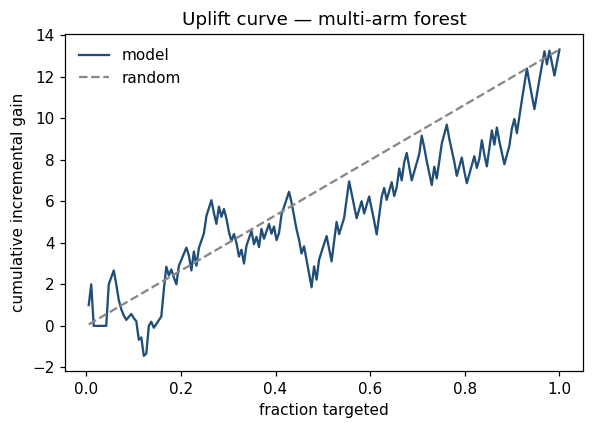

In [14]:
plot_uplift_curve(
    auuc_metrics["conversion"],
    auuc_metrics["is_treated"],
    auuc_metrics["uplift_tree"],
    title="Uplift curve — multi-arm forest",
)
print("Qini coefficient:", round(qini_coefficient(
    auuc_metrics["conversion"], auuc_metrics["is_treated"], auuc_metrics["uplift_tree"]
), 4))
plt.show()


### Binary subset (control vs treatment1) for tree visualization and KL forest

The sections below follow the one-control/one-treatment setup from the [Python uplift tree visualization](https://causalml.readthedocs.io/en/latest/examples/uplift_tree_visualization.html) example. We restrict `df` to `control` and `treatment1`, then split into training and test matrices (column names are required for SHAP).


In [15]:
rng_bin = np.random.default_rng(111)
df_bin = df[df["treatment_group_key"].isin(["control", "treatment1"])].reset_index(drop=True)
X_all = df_bin[x_names].to_numpy()
y_all = df_bin["conversion"].to_numpy()
w_all = (df_bin["treatment_group_key"].to_numpy() != "control").astype(int)
idx_bin = rng_bin.choice(len(df_bin), size=int(0.8 * len(df_bin)), replace=False)
test_bin = np.setdiff1d(np.arange(len(df_bin)), idx_bin)
X_train, y_train, w_train = X_all[idx_bin], y_all[idx_bin], w_all[idx_bin]
X_test_bin, y_test, w_test = X_all[test_bin], y_all[test_bin], w_all[test_bin]
print(X_train.shape, X_test_bin.shape)


(774, 10) (194, 10)


### Print uplift tree as a string

In [16]:
uplift_model_bin = UpliftTree(
    criterion="kl", max_depth=4, min_samples_leaf=40, min_samples_treatment=10, random_state=111
)
uplift_model_bin.fit(X_train, w_train, y_train, feature_names=x_names)
print(format_uplift_tree(uplift_model_bin))


[x5 <= -0.918]  gain=0.0131  tau=0.016  n=774
  [x7 <= 0.094]  gain=0.0847  tau=-0.150  n=155
    * leaf  tau=-0.350  n=78
    * leaf  tau=0.054  n=77
  [x0 <= 0.485]  gain=0.0195  tau=0.053  n=619
    [x1 <= -0.062]  gain=0.0142  tau=-0.019  n=402
      [x8 <= 0.057]  gain=0.0738  tau=-0.095  n=201
        * leaf  tau=-0.282  n=101
        * leaf  tau=0.097  n=100
      [x9 <= -0.388]  gain=0.0460  tau=0.073  n=201
        * leaf  tau=-0.131  n=71
        * leaf  tau=0.184  n=130
    [x2 <= -0.793]  gain=0.1218  tau=0.180  n=217
      * leaf  tau=0.603  n=44
      [x9 <= 0.328]  gain=0.0581  tau=0.085  n=173
        * leaf  tau=-0.019  n=112
        * leaf  tau=0.287  n=61


### Read the tree

- **Split line**: feature and threshold, with the gain of that split.
- **tau**: treatment-minus-control outcome at that node. On a leaf this is the uplift score.
- **n**: number of training rows in the node.
- Leaves with a positive uplift are the Persuadable region; a negative uplift flags Do-Not-Disturbs.

There is no separate validation-fill step. The next cell compares the mean predicted uplift on the training rows and the test rows.


### Plot the uplift tree

Edges are drawn with **arrows** from each split to its children (aligned with [Python CausalML's graphviz style](https://causalml.readthedocs.io/en/latest/examples/uplift_tree_visualization.html)).


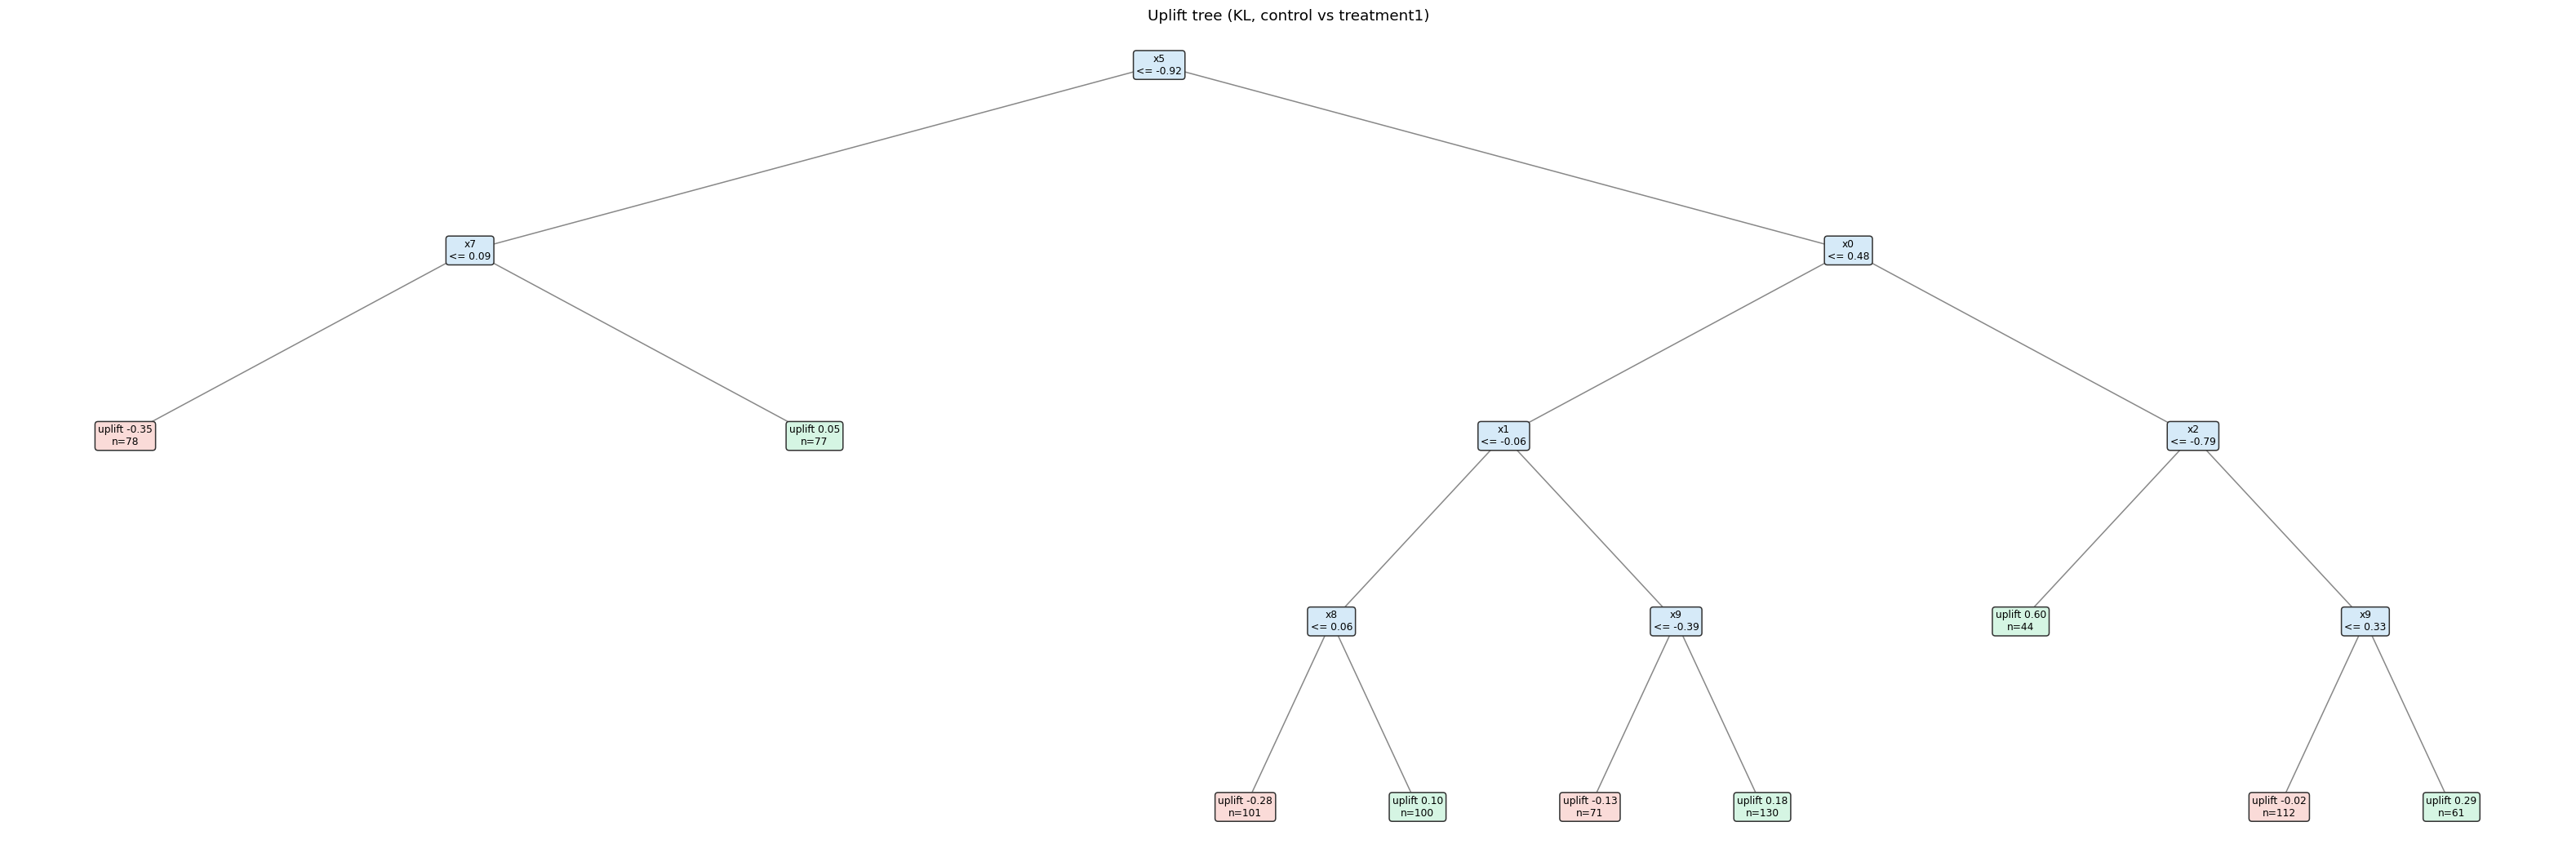

In [17]:
plot_uplift_tree(uplift_model_bin, title="Uplift tree (KL, control vs treatment1)")
plt.show()


### Train versus test uplift

The fitted tree is scored on the training matrix and the test matrix. A large gap in mean predicted uplift is a warning that the tree is fitting noise.


In [18]:
pred_train = uplift_model_bin.predict(X_train)
pred_test = uplift_model_bin.predict(X_test_bin)
print(
    "Mean predicted CATE — train:", round(float(pred_train.mean()), 4),
    " test:", round(float(pred_test.mean()), 4),
)


Mean predicted CATE — train: 0.0188  test: -0.0165


### Print and plot one tree in the forest

`UpliftRandomForest.trees_` holds the fitted trees. The first tree is `trees_[0]`.


In [19]:
uplift_rf = UpliftRandomForest(
    criterion="kl", n_trees=5, max_depth=4, min_samples_leaf=30, random_state=111
)
uplift_rf.fit(X_train, w_train, y_train, feature_names=x_names)
print("Trees:", len(uplift_rf.trees_))


Trees: 5


### Forest plot

The panels below are four trees from the same forest. Leaf color follows the sign of the uplift: green when the leaf uplift is positive, red when it is negative.


In [20]:
print(format_uplift_tree(uplift_rf.trees_[0]))


[x3 <= 0.434]  gain=0.0312  tau=0.035  n=774
  [x1 <= 0.203]  gain=0.0864  tau=-0.037  n=504
    [x8 <= 0.105]  gain=0.0789  tau=-0.180  n=327
      [x4 <= -0.707]  gain=0.1641  tau=-0.377  n=164
        * leaf  tau=-0.139  n=33
        * leaf  tau=-0.501  n=131
      [x5 <= 0.478]  gain=0.3266  tau=0.010  n=163
        * leaf  tau=-0.207  n=106
        * leaf  tau=0.396  n=57
    [x1 <= 0.453]  gain=0.1268  tau=0.249  n=177
      * leaf  tau=0.664  n=37
      [x3 <= -0.705]  gain=0.0892  tau=0.148  n=140
        * leaf  tau=0.427  n=49
        * leaf  tau=-0.003  n=91
  [x4 <= -0.842]  gain=0.0756  tau=0.205  n=270
    * leaf  tau=-0.104  n=54
    [x3 <= 0.589]  gain=0.0929  tau=0.298  n=216
      * leaf  tau=0.663  n=46
      [x4 <= 0.416]  gain=0.0950  tau=0.214  n=170
        * leaf  tau=0.179  n=112
        * leaf  tau=0.366  n=58


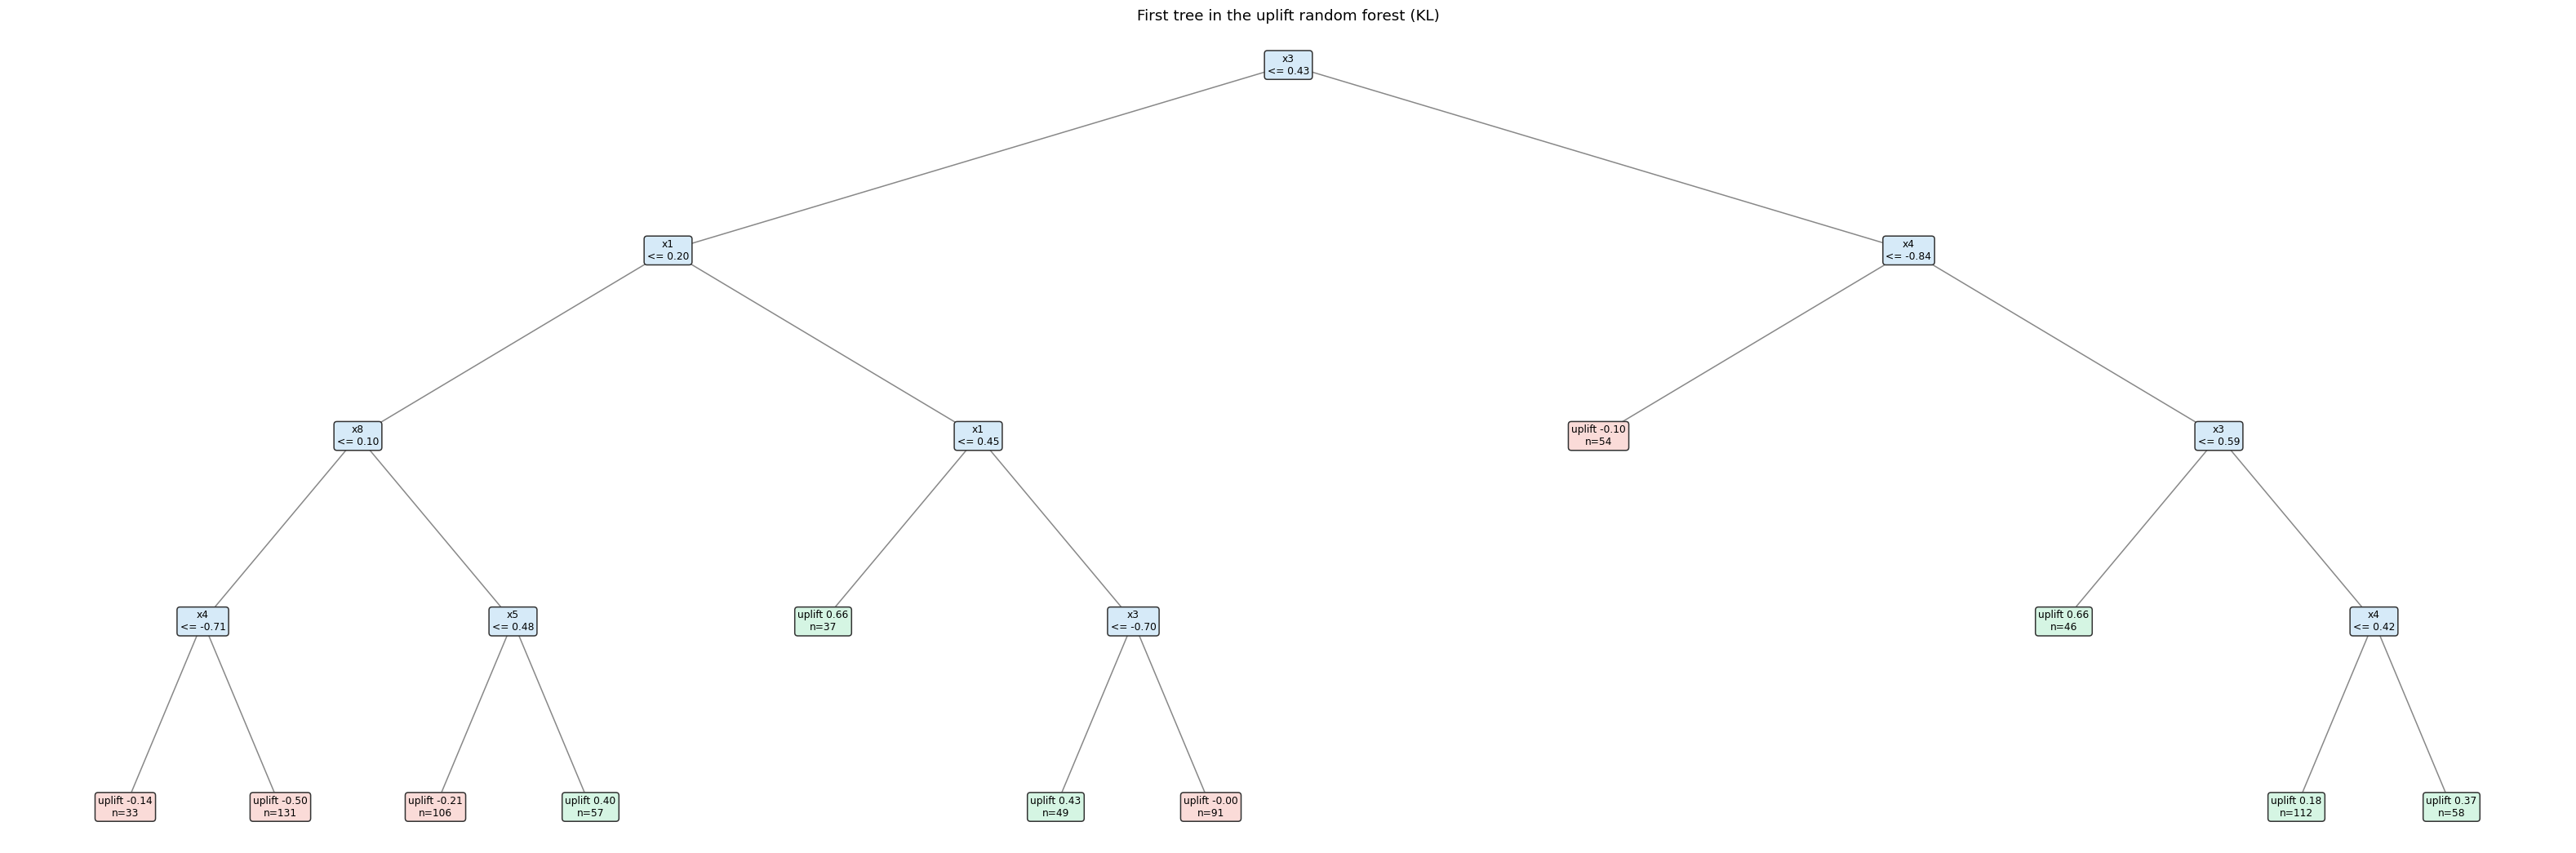

In [21]:
plot_uplift_tree(uplift_rf.trees_[0], title="First tree in the uplift random forest (KL)")
plt.show()


### Fill the tree with validation data

Score the fitted forest on the test set and compare the mean predicted CATE with the training set. A large gap is a sign that the forest is fitting noise.

### Forest visualization: plot multiple trees in a grid

Visualize several trees from the same forest (R equivalent of plotting `uplift_forest[0]`, `uplift_forest[1]`, ... in Python):


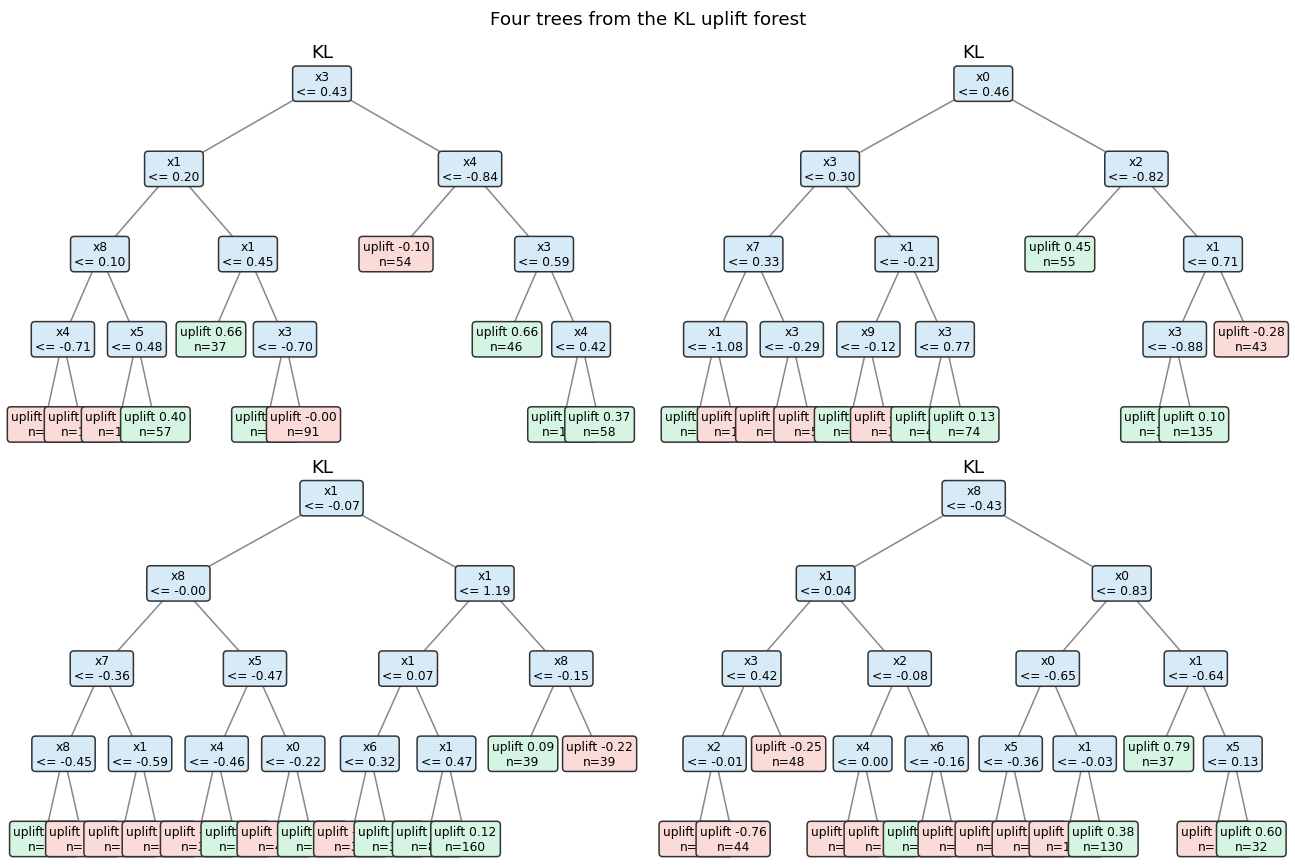

In [22]:
plot_forest(uplift_rf, title="Four trees from the KL uplift forest")
plt.show()


Optional: color leaves by uplift (tau):

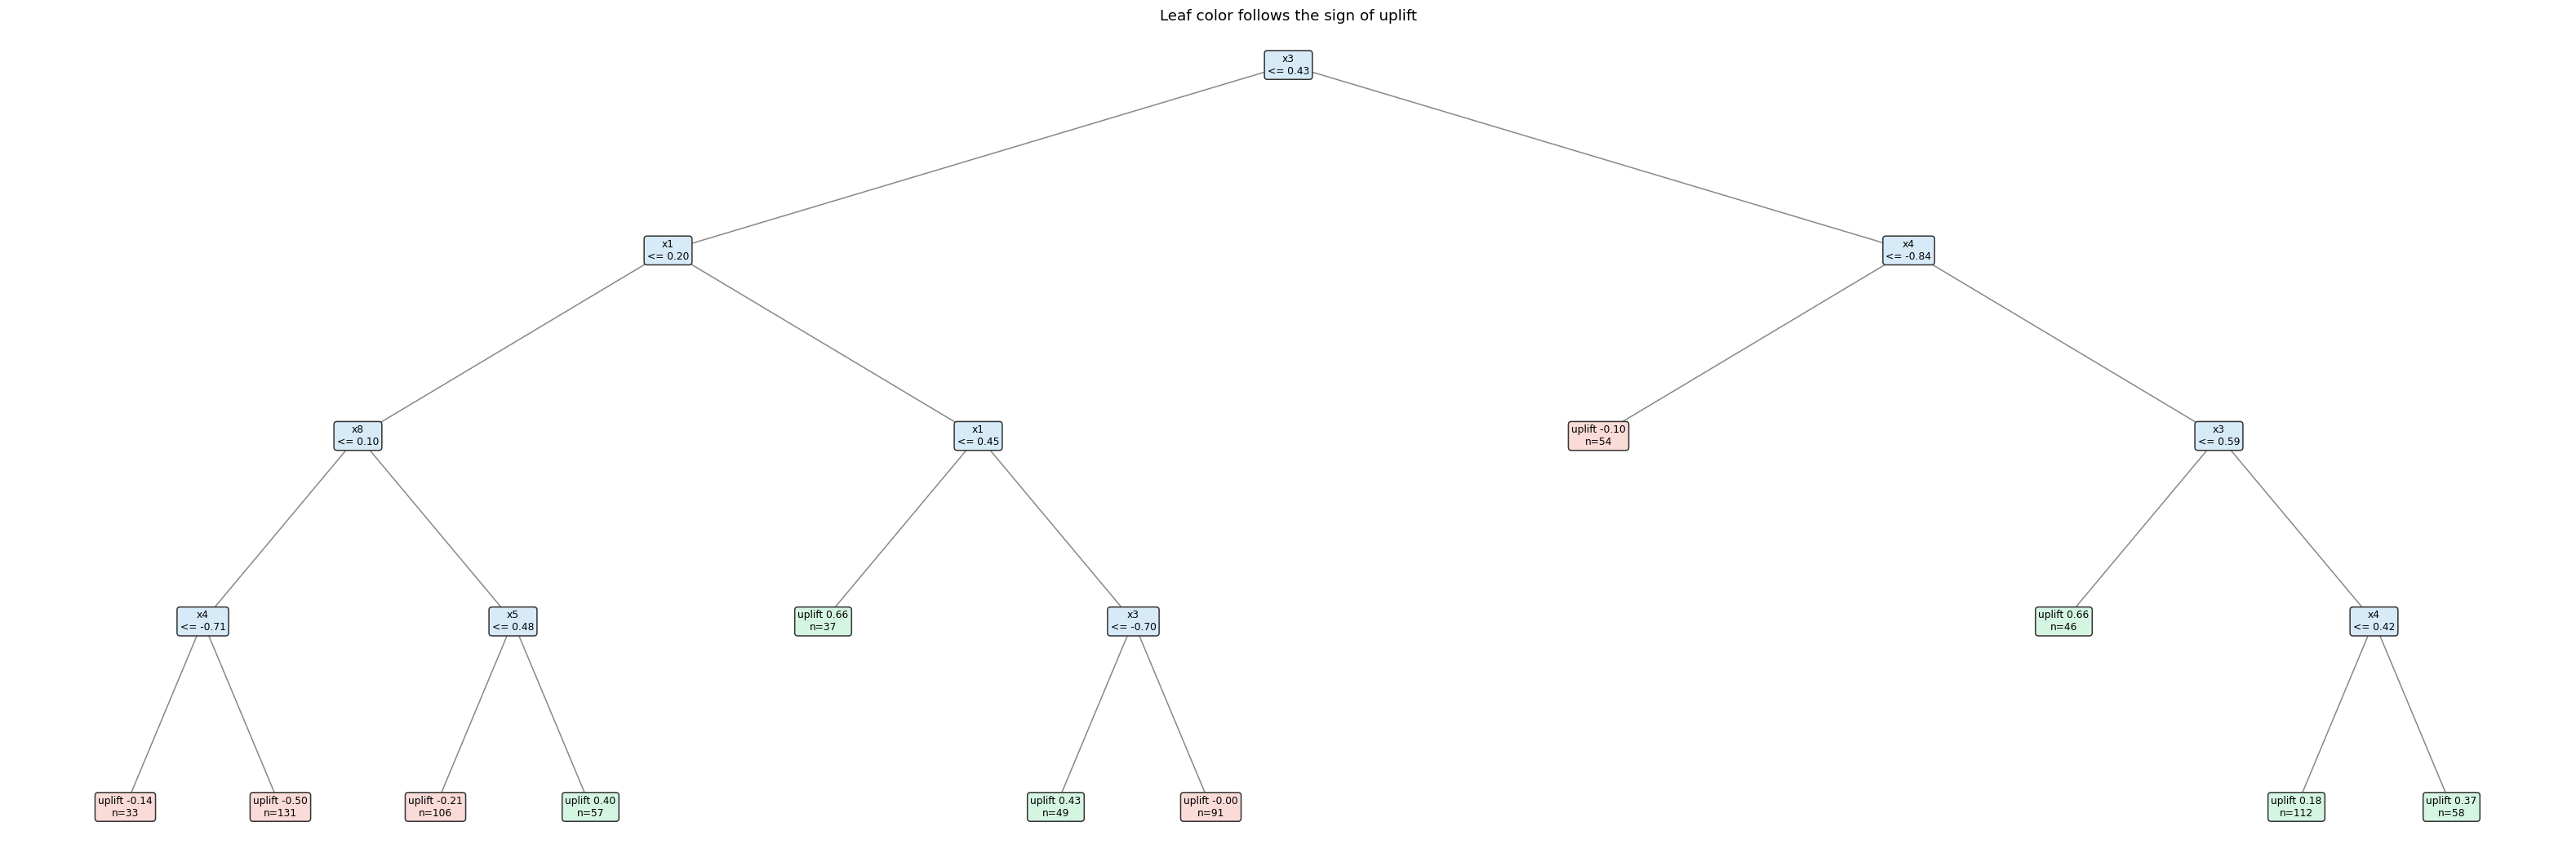

In [23]:
# Leaf boxes are green when uplift is positive and red when it is negative.
plot_uplift_tree(uplift_rf.trees_[0], title="Leaf color follows the sign of uplift")
plt.show()


## One control + multiple treatments

As in the [Python example](https://causalml.readthedocs.io/en/latest/examples/uplift_tree_visualization.html), we use the full dataset with control and multiple treatments. The uplift score at each node represents the **best uplift among all treatment effects** (Python: "The uplift score represents the best uplift score among all treatment effects").


In [24]:
df_multi, X_names_multi = make_uplift_classification(
    treatment_name=("control", "treatment1", "treatment2", "treatment3"),
    y_name="conversion",
    n_samples=2000,
    n_classification_features=10,
    n_classification_informative=5,
    n_uplift_increase_dict={"treatment1": 5, "treatment2": 5, "treatment3": 5},
    n_uplift_decrease_dict={"treatment1": 3, "treatment2": 3, "treatment3": 3},
    delta_uplift_increase_dict={"treatment1": 0.1, "treatment2": 0.15, "treatment3": 0.2},
    delta_uplift_decrease_dict={"treatment1": -0.1, "treatment2": -0.1, "treatment3": -0.1},
    random_seed=111,
)


Look at the conversion rate and sample size in each group (Python: `pivot_table(values='conversion', index='treatment_group_key', aggfunc=[np.mean, np.size], margins=True)`):

In [25]:
summary_multi = (
    df_multi.groupby("treatment_group_key")["conversion"].agg(mean="mean", size="size")
)
summary_multi.loc["All"] = [df_multi["conversion"].mean(), len(df_multi)]
print(summary_multi.round(4))


                       mean    size
treatment_group_key                
control              0.4763   464.0
treatment1           0.4980   504.0
treatment2           0.5120   502.0
treatment3           0.5660   530.0
All                  0.5145  2000.0


Split the sample and fit one KL uplift tree on control versus any treatment. The leaf value is the uplift of receiving one of the active treatments rather than control.


In [26]:
rng_m = np.random.default_rng(111)
idx_m = rng_m.choice(len(df_multi), size=int(0.8 * len(df_multi)), replace=False)
w_multi = (df_multi["treatment_group_key"].to_numpy() != "control").astype(int)
X_multi = df_multi[X_names_multi].to_numpy()
y_multi = df_multi["conversion"].to_numpy()
print("Any-treatment rate:", round(float(w_multi.mean()), 3))


Any-treatment rate: 0.768


In [27]:
uplift_model_multi = UpliftTree(
    criterion="kl", max_depth=3, min_samples_leaf=40, min_samples_treatment=10, random_state=111
)
uplift_model_multi.fit(X_multi[idx_m], w_multi[idx_m], y_multi[idx_m], feature_names=X_names_multi)
print(format_uplift_tree(uplift_model_multi))


[x1 <= -0.035]  gain=0.0092  tau=0.059  n=1600
  [x2 <= -0.856]  gain=0.0215  tau=-0.012  n=800
    [x2 <= -1.422]  gain=1.2138  tau=0.170  n=160
      * leaf  tau=0.311  n=56
      * leaf  tau=0.104  n=104
    [x8 <= 0.045]  gain=0.0176  tau=-0.046  n=640
      * leaf  tau=-0.139  n=320
      * leaf  tau=0.048  n=320
  [x1 <= 1.222]  gain=0.0137  tau=0.126  n=800
    [x8 <= 0.327]  gain=0.0218  tau=0.168  n=640
      * leaf  tau=0.105  n=416
      * leaf  tau=0.298  n=224
    [x0 <= -0.520]  gain=0.1133  tau=-0.001  n=160
      * leaf  tau=-0.288  n=56
      * leaf  tau=0.154  n=104


### Plot uplift tree (multiple treatments)

The uplift score at each node represents the best uplift among all treatment effects (as in the Python example).


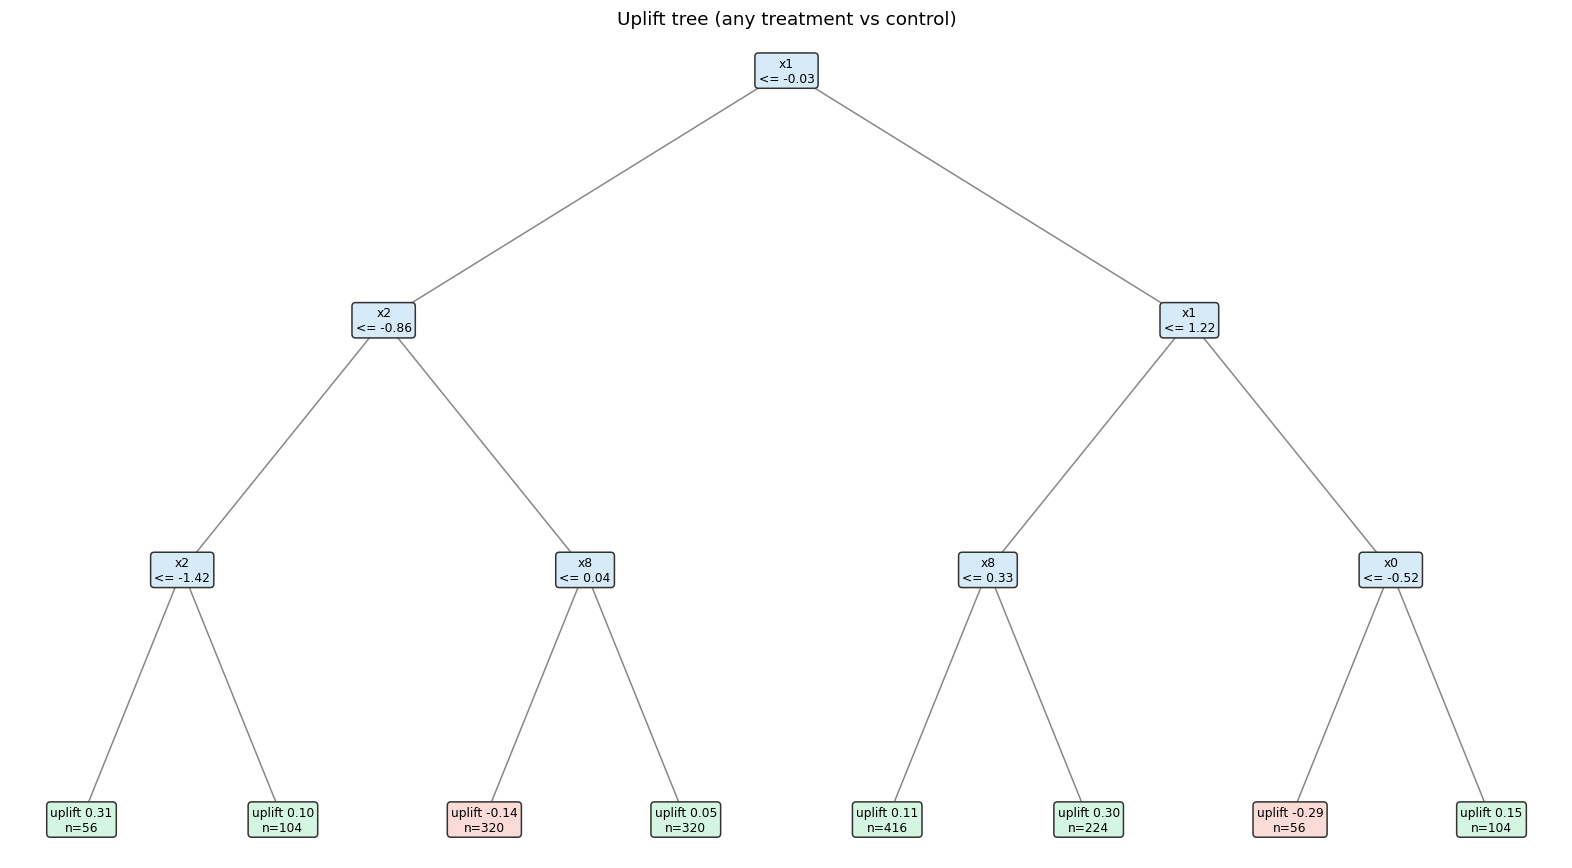

In [28]:
plot_uplift_tree(uplift_model_multi, title="Uplift tree (any treatment vs control)")
plt.show()


### Predicted CATE distribution (forest)

As an extra visualization, fit a forest and plot the distribution of predicted CATE across units.

In [29]:
uf = UpliftRandomForest(criterion="kl", n_trees=5, max_depth=4, min_samples_leaf=25, random_state=111)
uf.fit(X_all, w_all, y_all, feature_names=x_names)
pred_cate = uf.predict(X_all)
print("Mean predicted CATE:", round(float(pred_cate.mean()), 4))


Mean predicted CATE: -0.0028


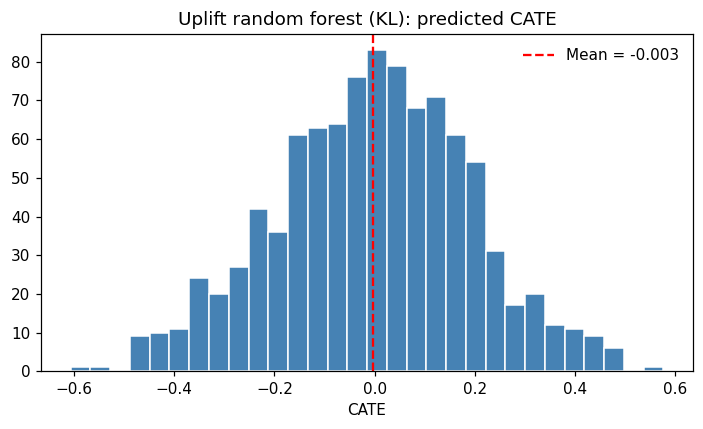

In [30]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.hist(pred_cate, bins=30, color="steelblue", edgecolor="white")
ax.axvline(pred_cate.mean(), color="red", ls="--", label=f"Mean = {pred_cate.mean():.3f}")
ax.set_xlabel("CATE")
ax.set_title("Uplift random forest (KL): predicted CATE")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


### Permutation SHAP for predicted uplift

`explain` attributes each unit's predicted uplift to covariates. We explain a subset of the training rows. Positive SHAP means the feature pushes predicted uplift up.

This explains heterogeneity in $\hat{\tau}(X)$, not the raw conversion probability.


In [31]:
sv = uplift_rf.explain(X_train, max_samples=30, n_permutations=6, random_state=2026)
print("SHAP array shape:", sv.values.shape)


SHAP array shape: (30, 10)


#### SHAP summary plot (beeswarm + importance)

This shows which covariates drive heterogeneity in predicted uplift the most, and in which direction.


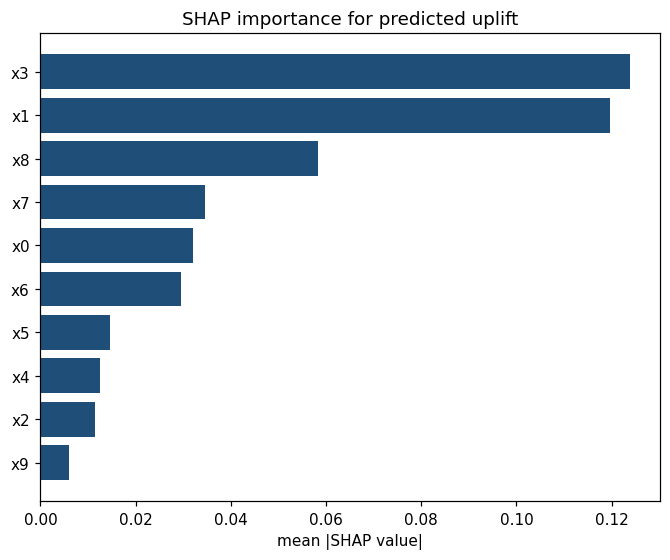

In [32]:
sv.plot_importance(title="SHAP importance for predicted uplift")
plt.show()


#### SHAP dependence plots (main effects)

Explore how individual covariates relate to the estimated uplift.


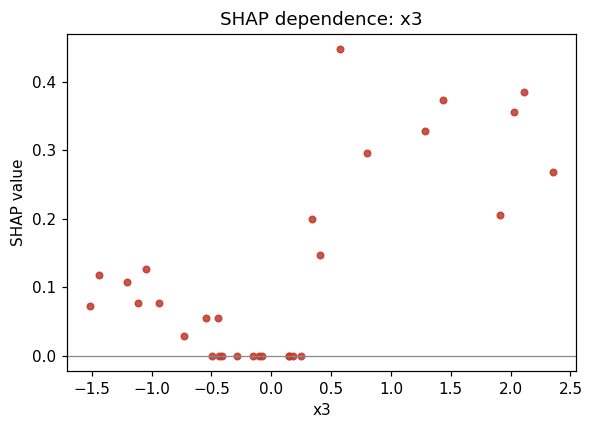

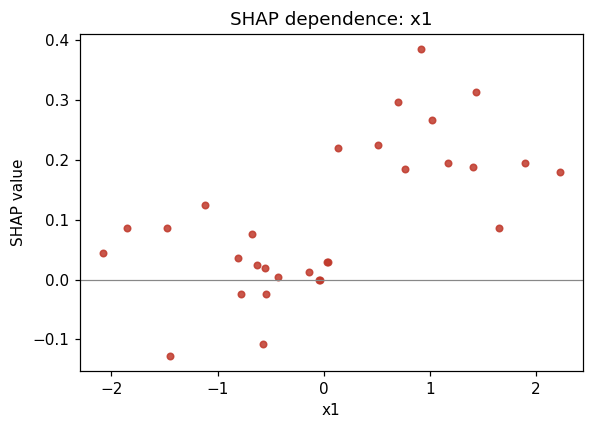

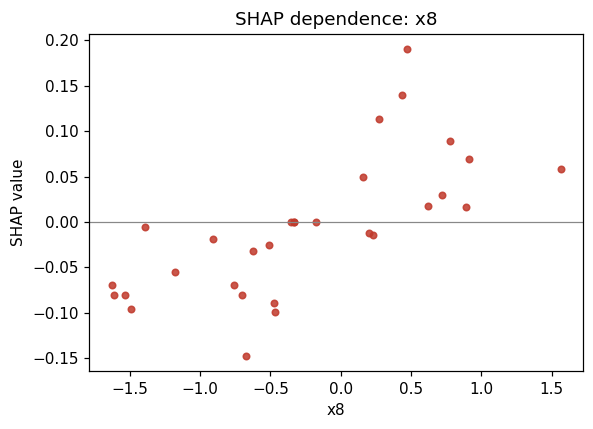

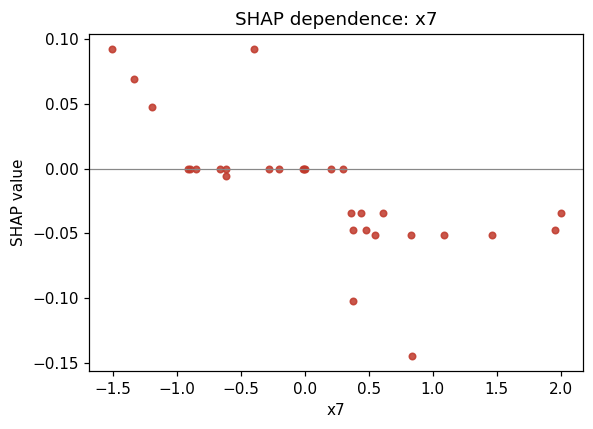

In [33]:
order = np.argsort(sv.importance())[::-1][:4]
for j in order:
    sv.plot_dependence(sv.feature_names[j])
    plt.show()


Single covariate with a color interaction:

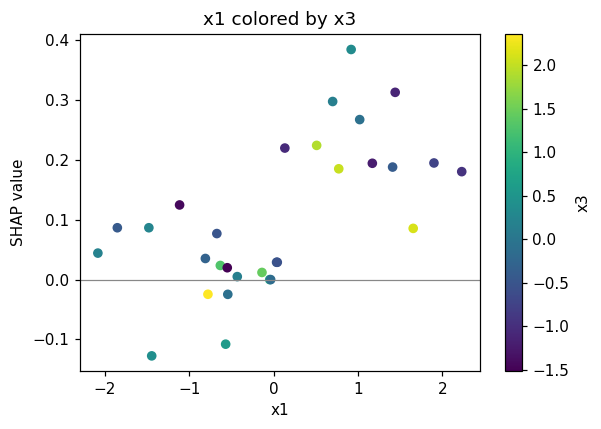

In [34]:
if len(order) >= 2:
    j, k = int(order[1]), int(order[0])
    fig, ax = plt.subplots(figsize=(5.6, 4))
    points = ax.scatter(sv.data[:, j], sv.values[:, j], c=sv.data[:, k], cmap="viridis", s=28)
    fig.colorbar(points, ax=ax, label=sv.feature_names[k])
    ax.axhline(0, color="#888888", lw=0.8)
    ax.set_xlabel(sv.feature_names[j])
    ax.set_ylabel("SHAP value")
    ax.set_title(f"{sv.feature_names[j]} colored by {sv.feature_names[k]}")
    fig.tight_layout()
    plt.show()


#### Waterfall / force plot for a single observation

Illustrates why a specific profile has high or low estimated uplift.


Highest predicted uplift in the explain set: 0.2935


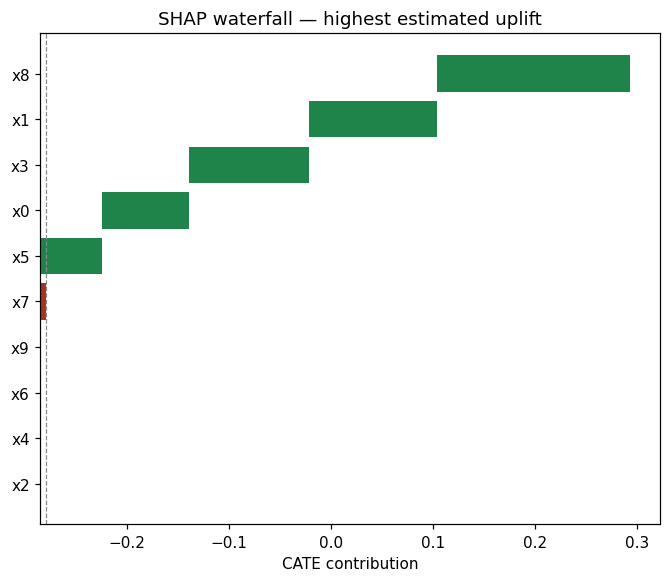

In [35]:
row_id = int(np.argmax(sv.predictions))
print("Highest predicted uplift in the explain set:", round(float(sv.predictions[row_id]), 4))
sv.plot_waterfall(row_id, title="SHAP waterfall — highest estimated uplift")
plt.show()


#### Optional: explain a few test rows

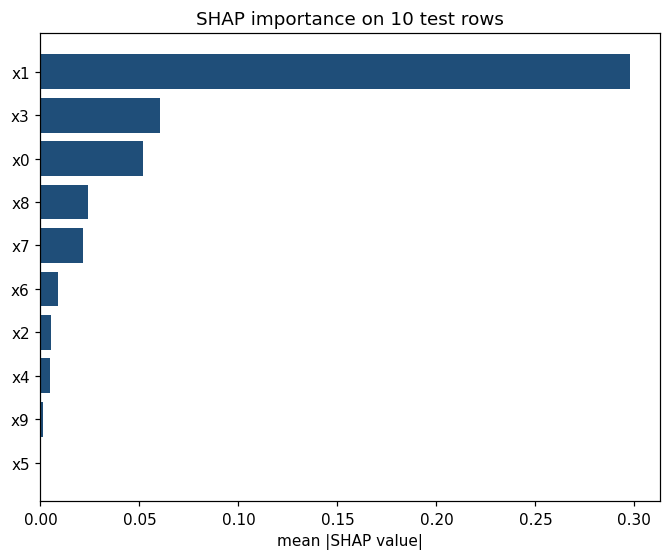

In [36]:
sv_test = uplift_rf.explain(X_test_bin[:10], max_samples=10, n_permutations=6, random_state=2026)
sv_test.plot_importance(title="SHAP importance on 10 test rows")
plt.show()


#### Interpretation notes

- **Positive SHAP** pushes predicted uplift up. **Negative SHAP** pushes it down.
- The explained quantity is $\hat{\tau}(X)$ from the uplift forest, not the conversion outcome.
- Dependence plots show how a covariate's contribution changes as its value changes.


## Summary and Conclusion

This notebook fitted uplift trees and uplift forests with PyCausalML on a synthetic multi-arm conversion experiment. One tree per treatment arm estimates the incremental effect of that arm relative to control. The Qini curve checks whether ranking units by predicted uplift captures more incremental conversions than random targeting. `explain` shows which features drive the predicted uplift.

Uplift models separate Persuadables from Sure Things. That ranking is what a targeting policy needs: treat people whose outcome changes because of the intervention.


## References

- [Uplift Trees Example with Synthetic Data (Python CausalML)](https://causalml.readthedocs.io/en/latest/examples/uplift_trees_with_synthetic_data.html)
- Gutierrez & Gérardy (2017), [Causal inference and uplift modelling: A review of the literature](http://proceedings.mlr.press/v67/gutierrez17a/gutierrez17a.pdf)
